<a href="https://colab.research.google.com/github/vigneshkv200/Bike-Sharing-Demand/blob/main/bike_rental_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Analysis

In [ ]:
import pandas as pd


In [ ]:
df=pd.read_csv("/content/day.csv")

In [ ]:
df.head(5)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [ ]:
df.shape

(731, 16)

In [ ]:
df.describe

<bound method NDFrame.describe of      instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0          1  2011-01-01       1   0     1        0        6           0   
1          2  2011-01-02       1   0     1        0        0           0   
2          3  2011-01-03       1   0     1        0        1           1   
3          4  2011-01-04       1   0     1        0        2           1   
4          5  2011-01-05       1   0     1        0        3           1   
..       ...         ...     ...  ..   ...      ...      ...         ...   
726      727  2012-12-27       1   1    12        0        4           1   
727      728  2012-12-28       1   1    12        0        5           1   
728      729  2012-12-29       1   1    12        0        6           0   
729      730  2012-12-30       1   1    12        0        0           0   
730      731  2012-12-31       1   1    12        0        1           1   

     weathersit      temp     atemp       hum  windspeed  casual  registered  \
0             2  0.344167  0.363625  0.805833   0.160446     331         654   
1             2  0.363478  0.353739  0.696087   0.248539     131         670   
2             1  0.196364  0.189405  0.437273   0.248309     120        1229   
3             1  0.200000  0.212122  0.590435   0.160296     108        1454   
4             1  0.226957  0.229270  0.436957   0.186900      82        1518   
..          ...       ...       ...       ...        ...     ...         ...   
726           2  0.254167  0.226642  0.652917   0.350133     247        1867   
727           2  0.253333  0.255046  0.590000   0.155471     644        2451   
728           2  0.253333  0.242400  0.752917   0.124383     159        1182   
729           1  0.255833  0.231700  0.483333   0.350754     364        1432   
730           2  0.215833  0.223487  0.577500   0.154846     439        2290   

      cnt  
0     985  
1     801  
2    1349  
3    1562  
4    1600  
..    ...  
726  2114  
727  3095  
728  1341  
729  1796  
730  2729  

[731 rows x 16 columns]>

In [ ]:
df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [ ]:
for i in df.columns:
    print(i,df[i].value_counts())

instant instant
731    1
1      1
2      1
3      1
4      1
      ..
16     1
15     1
14     1
13     1
12     1
Name: count, Length: 731, dtype: int64
dteday dteday
2012-12-31    1
2011-01-01    1
2011-01-02    1
2011-01-03    1
2011-01-04    1
             ..
2011-01-16    1
2011-01-15    1
2011-01-14    1
2011-01-13    1
2011-01-12    1
Name: count, Length: 731, dtype: int64
season season
3    188
2    184
1    181
4    178
Name: count, dtype: int64
yr yr
1    366
0    365
Name: count, dtype: int64
mnth mnth
1     62
3     62
7     62
5     62
12    62
10    62
8     62
4     60
9     60
6     60
11    60
2     57
Name: count, dtype: int64
holiday holiday
0    710
1     21
Name: count, dtype: int64
weekday weekday
6    105
0    105
1    105
2    104
3    104
4    104
5    104
Name: count, dtype: int64
workingday workingday
1    500
0    231
Name: count, dtype: int64
weathersit weathersit
1    463
2    247
3     21
Name: count, dtype: int64
temp temp
0.265833    5
0.635000    5
0.5

In [ ]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')

In [ ]:
categorical_cols = [
    'season', 'yr', 'mnth', 'holiday',
    'weekday', 'workingday', 'weathersit'
]

numerical_cols = [
    'temp', 'atemp', 'hum', 'windspeed'
]

target_cols = [
    'casual', 'registered', 'cnt'
]

date_col = ['dteday']

id_col = ['instant']

In [ ]:
df[categorical_cols].value_counts(dropna =False)

season  yr  mnth  holiday  weekday  workingday  weathersit
4       1   11    0        5        1           1             5
3       0   8     0        2        1           1             5
            7     0        6        0           1             5
        1   8     0        4        1           1             5
        0   8     0        1        1           1             5
                                                             ..
4       1   12    0        1        1           1             1
1       0   1     0        2        1           1             1
                  1        1        0           2             1
                  0        1        1           2             1
                           0        0           2             1
Name: count, Length: 397, dtype: int64

In [ ]:
for i in categorical_cols:
    print(i,df[i].value_counts())

season season
3    188
2    184
1    181
4    178
Name: count, dtype: int64
yr yr
1    366
0    365
Name: count, dtype: int64
mnth mnth
1     62
3     62
7     62
5     62
12    62
10    62
8     62
4     60
9     60
6     60
11    60
2     57
Name: count, dtype: int64
holiday holiday
0    710
1     21
Name: count, dtype: int64
weekday weekday
6    105
0    105
1    105
2    104
3    104
4    104
5    104
Name: count, dtype: int64
workingday workingday
1    500
0    231
Name: count, dtype: int64
weathersit weathersit
1    463
2    247
3     21
Name: count, dtype: int64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


##### Outlier Analysis

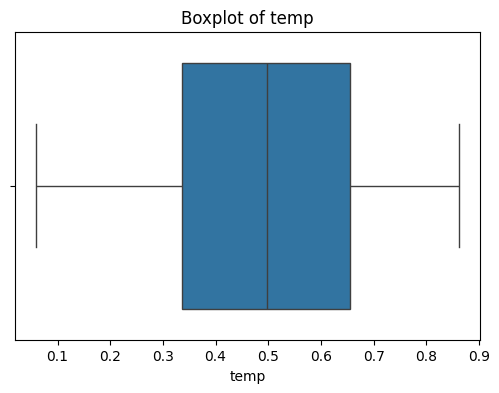

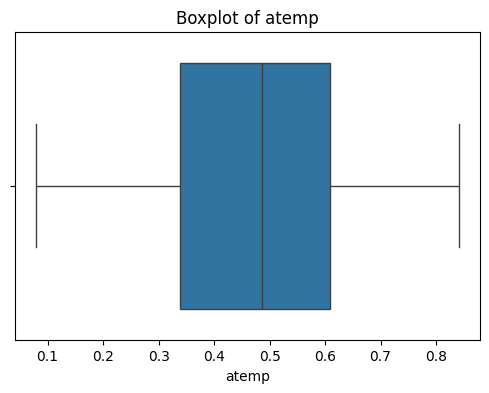

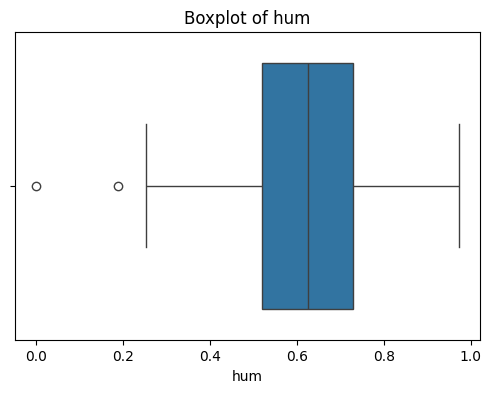

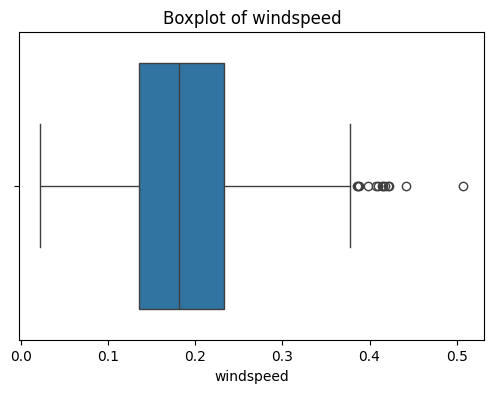

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numerical_cols:
    plt.figure(figsize =(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

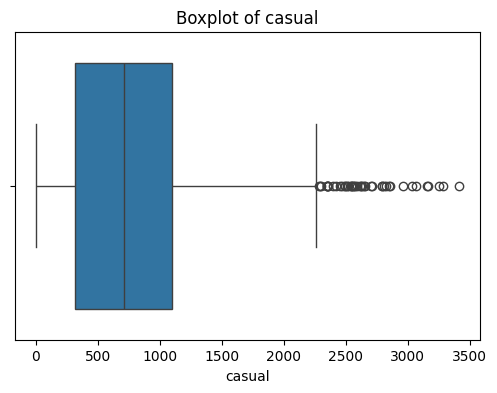

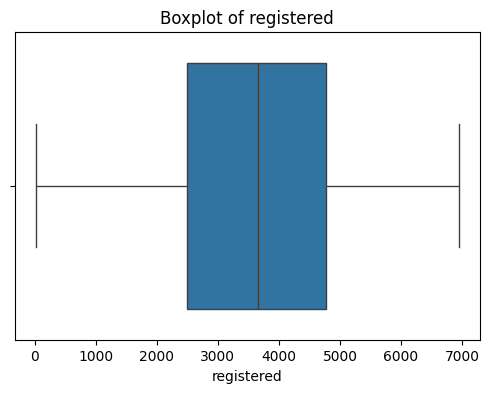

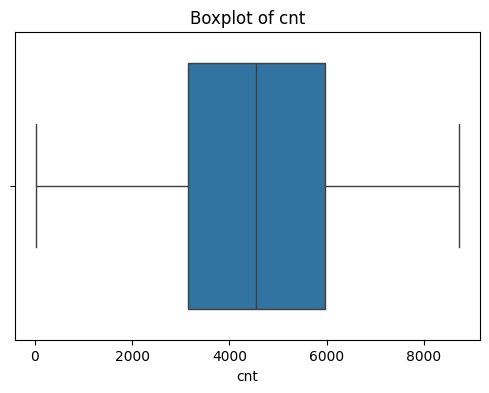

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in target_cols:
    plt.figure(figsize =(6,4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [ ]:
skew_cols = [
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'casual',
    'registered',
    'cnt'
]

df[skew_cols].skew().sort_values()


,0
atemp,-0.131088
hum,-0.069783
temp,-0.054521
cnt,-0.047353
registered,0.043659
windspeed,0.677345
casual,1.266454


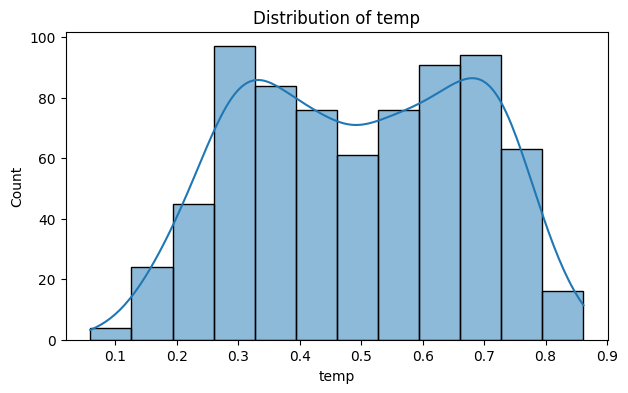

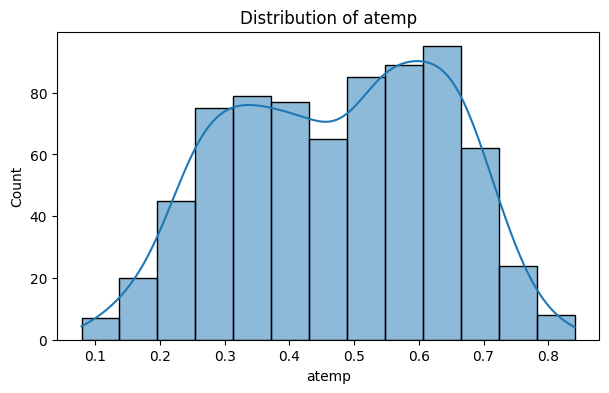

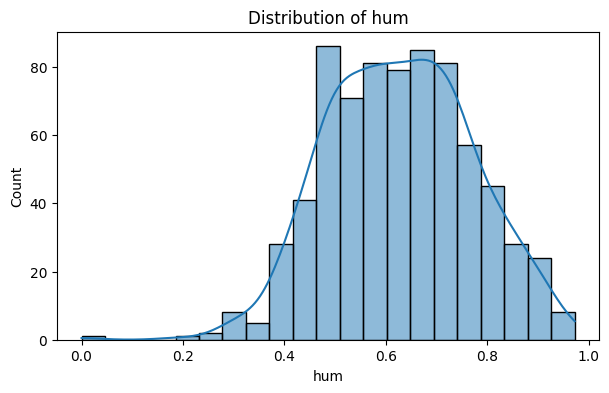

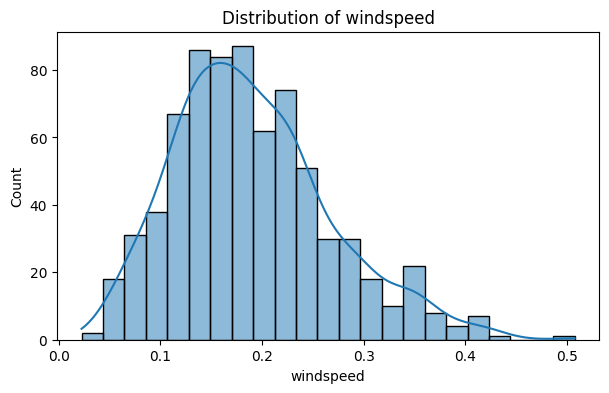

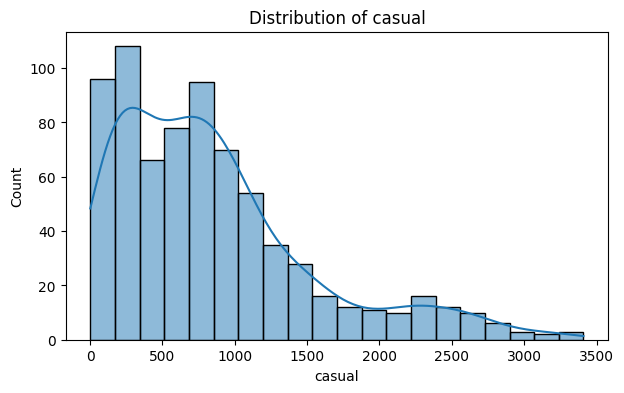

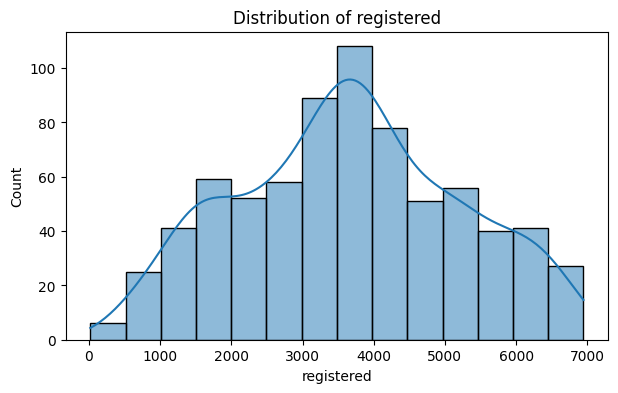

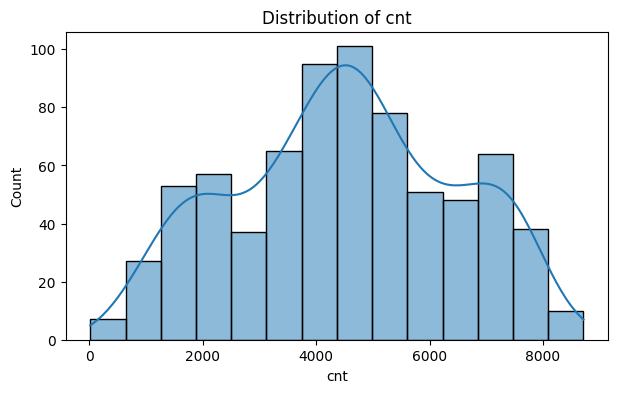

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in skew_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()

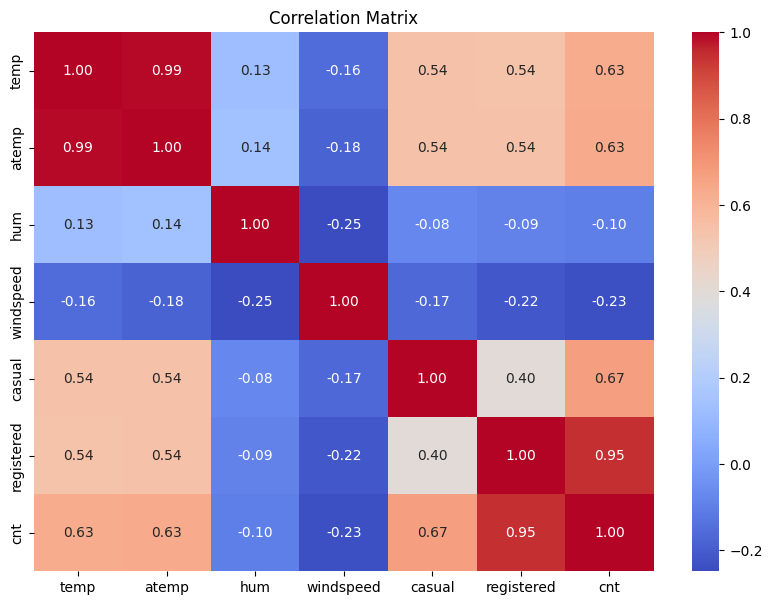

In [ ]:
corr_cols = [
    'temp',
    'atemp',
    'hum',
    'windspeed',
    'casual',
    'registered',
    'cnt'
]

plt.figure(figsize=(10, 7))
sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix')
plt.show()

### Model Prediction

In [ ]:

# BOX 23 - FEATURE SELECTION

# Columns removed based on EDA
drop_cols = [
    'instant',   # Record/index column
    'dteday',    # Date information already represented by other features
    'temp'       # Highly correlated with atemp (~0.99)
]

df_model = df.drop(columns=drop_cols).copy()

print("Removed columns:", drop_cols)
print("\nRemaining columns:")
print(df_model.columns.tolist())
print("\nShape:", df_model.shape)

Removed columns: ['instant', 'dteday', 'temp']

Remaining columns:
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Shape: (731, 13)


In [ ]:

# BOX 24 - FEATURE GROUPS

categorical_cols = [
    'season',
    'mnth',
    'weekday'
]

weather_col = [
    'weathersit'
]

binary_cols = [
    'yr',
    'holiday',
    'workingday'
]

numerical_cols = [
    'atemp',
    'hum',
    'windspeed'
]

target_cols = [
    'casual',
    'registered',
    'cnt'
]

print("Categorical columns:", categorical_cols)
print("Weather column:", weather_col)
print("Binary columns:", binary_cols)
print("Numerical columns:", numerical_cols)
print("Target columns:", target_cols)


Categorical columns: ['season', 'mnth', 'weekday']
Weather column: ['weathersit']
Binary columns: ['yr', 'holiday', 'workingday']
Numerical columns: ['atemp', 'hum', 'windspeed']
Target columns: ['casual', 'registered', 'cnt']


In [ ]:

# BOX 25 - FEATURES AND TARGET

X = df_model.drop(columns=['casual', 'registered', 'cnt'])
y = df_model['cnt']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

X shape: (731, 10)
y shape: (731,)

Features:
['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'atemp', 'hum', 'windspeed']

Target:
cnt


In [ ]:
X

,season,yr,mnth,holiday,weekday,workingday,weathersit,atemp,hum,windspeed
0,1,0,1,0,6,0,2,0.363625,0.805833,0.160446
1,1,0,1,0,0,0,2,0.353739,0.696087,0.248539
2,1,0,1,0,1,1,1,0.189405,0.437273,0.248309
3,1,0,1,0,2,1,1,0.212122,0.590435,0.160296
4,1,0,1,0,3,1,1,0.229270,0.436957,0.186900
...,...,...,...,...,...,...,...,...,...,...
726,1,1,12,0,4,1,2,0.226642,0.652917,0.350133
727,1,1,12,0,5,1,2,0.255046,0.590000,0.155471
728,1,1,12,0,6,0,2,0.242400,0.752917,0.124383
729,1,1,12,0,0,0,1,0.231700,0.483333,0.350754


In [ ]:
# BOX 26
# Season-wise 80/20 Train-Test Split

from sklearn.model_selection import train_test_split

train_parts = []
test_parts = []

for season in df_model['season'].unique():

    season_data = df_model[df_model['season'] == season]

    train_season, test_season = train_test_split(
        season_data,
        test_size=0.20,
        random_state=42
    )

    train_parts.append(train_season)
    test_parts.append(test_season)

train_df = pd.concat(train_parts).sample(frac=1, random_state=42).reset_index(drop=True)
test_df = pd.concat(test_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

print("\nSeason distribution in training:")
print(train_df['season'].value_counts(normalize=True).sort_index())

print("\nSeason distribution in testing:")
print(test_df['season'].value_counts(normalize=True).sort_index())

Training shape: (583, 13)
Testing shape : (148, 13)

Season distribution in training:
season
1    0.246998
2    0.252144
3    0.257290
4    0.243568
Name: proportion, dtype: float64

Season distribution in testing:
season
1    0.250000
2    0.250000
3    0.256757
4    0.243243
Name: proportion, dtype: float64


In [ ]:
# BOX 27
# Compare target distribution between training and testing data

print("Training target statistics:")
print(train_df['cnt'].describe())

print("\nTesting target statistics:")
print(test_df['cnt'].describe())

print("\nTarget means:")
print("Training mean:", train_df['cnt'].mean())
print("Testing mean :", test_df['cnt'].mean())

print("\nTarget medians:")
print("Training median:", train_df['cnt'].median())
print("Testing median :", test_df['cnt'].median())

Training target statistics:
count     583.000000
mean     4534.662093
std      1956.164584
min        22.000000
25%      3204.000000
50%      4548.000000
75%      6043.000000
max      8714.000000
Name: cnt, dtype: float64

Testing target statistics:
count     148.000000
mean     4384.939189
std      1862.300356
min       623.000000
25%      3066.500000
50%      4537.000000
75%      5564.750000
max      7865.000000
Name: cnt, dtype: float64

Target means:
Training mean: 4534.662092624357
Testing mean : 4384.939189189189

Target medians:
Training median: 4548.0
Testing median : 4537.0


In [ ]:
# BOX 28
# Cyclic encoding for month and weekday

import numpy as np

for df in [train_df, test_df]:

    df['mnth_sin'] = np.sin(2 * np.pi * df['mnth'] / 12)
    df['mnth_cos'] = np.cos(2 * np.pi * df['mnth'] / 12)

    df['weekday_sin'] = np.sin(2 * np.pi * df['weekday'] / 7)
    df['weekday_cos'] = np.cos(2 * np.pi * df['weekday'] / 7)

print("Cyclic features created successfully.")

print(
    train_df[
        ['mnth', 'mnth_sin', 'mnth_cos',
         'weekday', 'weekday_sin', 'weekday_cos']
    ].head()
)


Cyclic features created successfully.
   mnth  mnth_sin      mnth_cos  weekday  weekday_sin  weekday_cos
0     7 -0.500000 -8.660254e-01        6    -0.781831     0.623490
1     8 -0.866025 -5.000000e-01        0     0.000000     1.000000
2     3  1.000000  6.123234e-17        6    -0.781831     0.623490
3     8 -0.866025 -5.000000e-01        4    -0.433884    -0.900969
4     4  0.866025 -5.000000e-01        5    -0.974928    -0.222521


In [ ]:

# BOX 29
# One-hot encoding for categorical features

from sklearn.preprocessing import OneHotEncoder

categorical_features = ['season', 'weathersit']

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore'
)

train_encoded = encoder.fit_transform(train_df[categorical_features])
test_encoded = encoder.transform(test_df[categorical_features])

encoded_columns = encoder.get_feature_names_out(categorical_features)

train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=train_df.index
)

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=test_df.index
)

print("Encoded features:")
print(encoded_columns)

print("\nEncoded training shape:", train_encoded_df.shape)
print("Encoded testing shape:", test_encoded_df.shape)


Encoded features:
['season_1' 'season_2' 'season_3' 'season_4' 'weathersit_1' 'weathersit_2'
 'weathersit_3']

Encoded training shape: (583, 7)
Encoded testing shape: (148, 7)


In [ ]:

# BOX 30
# Build final feature matrices

# Numerical + binary features
numeric_features = [
    'yr',
    'holiday',
    'workingday',
    'atemp',
    'hum',
    'windspeed',
    'mnth_sin',
    'mnth_cos',
    'weekday_sin',
    'weekday_cos'
]

# Keep original month/weekday out because their cyclic versions are used
# Keep season/weathersit out because they are one-hot encoded
# Drop dteday, instant, casual, registered and cnt

train_numeric = train_df[numeric_features].reset_index(drop=True)
test_numeric = test_df[numeric_features].reset_index(drop=True)

train_encoded_df = train_encoded_df.reset_index(drop=True)
test_encoded_df = test_encoded_df.reset_index(drop=True)

X_train = pd.concat(
    [train_numeric, train_encoded_df],
    axis=1
)

X_test = pd.concat(
    [test_numeric, test_encoded_df],
    axis=1
)

y_train = train_df['cnt'].reset_index(drop=True)
y_test = test_df['cnt'].reset_index(drop=True)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("\nFinal features:")
print(X_train.columns.tolist())

X_train shape: (583, 17)
X_test shape : (148, 17)

Final features:
['yr', 'holiday', 'workingday', 'atemp', 'hum', 'windspeed', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos', 'season_1', 'season_2', 'season_3', 'season_4', 'weathersit_1', 'weathersit_2', 'weathersit_3']


In [ ]:

# BOX 31
# 5-Fold Cross Validation setup

from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy:")
print(cv)

print("\nNumber of folds:", cv.get_n_splits(X_train))


Cross-validation strategy:
KFold(n_splits=5, random_state=42, shuffle=True)

Number of folds: 5


In [ ]:
# BOX 32
# Log transformation of the target

y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Original training target:")
print(y_train.describe())

print("\nLog-transformed training target:")
print(y_train_log.describe())


Original training target:
count     583.000000
mean     4534.662093
std      1956.164584
min        22.000000
25%      3204.000000
50%      4548.000000
75%      6043.000000
max      8714.000000
Name: cnt, dtype: float64

Log-transformed training target:
count    583.000000
mean       8.288333
std        0.592737
min        3.135494
25%        8.072463
50%        8.422663
75%        8.706821
max        9.072801
Name: cnt, dtype: float64


In [ ]:

# BOX 33
# StandardScaler preparation for scale-sensitive models

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

print("\nScaled feature means:")
print(X_train_scaled.mean().round(4))

Scaled training shape: (583, 17)
Scaled testing shape : (148, 17)

Scaled feature means:
yr             -0.0
holiday        -0.0
workingday     -0.0
atemp           0.0
hum             0.0
windspeed       0.0
mnth_sin       -0.0
mnth_cos       -0.0
weekday_sin     0.0
weekday_cos    -0.0
season_1       -0.0
season_2        0.0
season_3       -0.0
season_4       -0.0
weathersit_1    0.0
weathersit_2    0.0
weathersit_3    0.0
dtype: float64


In [ ]:

# BOX 34
# Model evaluation function

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import time

def evaluate_model(y_true, y_pred_log, cv_rmse=None, cv_mae=None, cv_r2=None):

    # Convert predictions back to original rental-count scale
    y_pred = np.expm1(y_pred_log)

    # Prevent negative rental predictions
    y_pred = np.maximum(y_pred, 0)

    test_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    test_mae = mean_absolute_error(y_true, y_pred)
    test_r2 = r2_score(y_true, y_pred)

    results = {
        'CV RMSE': cv_rmse,
        'CV MAE': cv_mae,
        'CV R2': cv_r2,
        'Test RMSE': test_rmse,
        'Test MAE': test_mae,
        'Test R2': test_r2
    }

    return results

In [ ]:
pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 2.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 71.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.2/132.2 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# BOX 35
# MLflow logging function - Updated

import mlflow

def log_mlflow_run(
    model_name,
    model,
    params,
    metrics,
    training_time,
    run_name=None
):

    if run_name is None:
        run_name = model_name

    with mlflow.start_run(run_name=run_name):

        # Log model name
        mlflow.log_param("model_name", model_name)

        # Log model parameters
        for param_name, param_value in params.items():
            mlflow.log_param(param_name, str(param_value))

        # Log metrics
        for metric_name, metric_value in metrics.items():
            if metric_value is not None:
                mlflow.log_metric(
                    metric_name,
                    float(metric_value)
                )

        # Log training time
        mlflow.log_metric(
            "training_time_seconds",
            float(training_time)
        )

        # Handle XGBoost trusted types
        if model_name == "XGBoost":

            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                skops_trusted_types=[
                    "xgboost.core.Booster",
                    "xgboost.sklearn.XGBRegressor"
                ]
            )
        elif model_name == "LightGBM":

            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                skops_trusted_types=[
                    "collections.OrderedDict",
                    "lightgbm.basic.Booster",
                    "lightgbm.sklearn.LGBMRegressor"
                ]
            )
        elif model_name == "CatBoost Tuned":

            mlflow.catboost.log_model(
                cb_model=model,
                name="model"
            )
        else:

            mlflow.sklearn.log_model(
                sk_model=model,
                name="model"
            )

        print(f"MLflow run logged successfully: {run_name}")

In [ ]:
# BOX 36
# Model 1 - Linear Regression

from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

print("Linear Regression model created.")
print(lr_model)

Linear Regression model created.
LinearRegression()


In [ ]:

# BOX 37
# Linear Regression - 5-Fold Cross Validation

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

cv_rmse_scores = []
cv_mae_scores = []
cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Scaling is fitted only on the fold's training data
    fold_model = Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ])

    fold_model.fit(X_fold_train, y_fold_train)

    val_pred_log = fold_model.predict(X_fold_val)

    # Convert back to original cnt scale
    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    cv_rmse_scores.append(fold_rmse)
    cv_mae_scores.append(fold_mae)
    cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

lr_cv_rmse = np.mean(cv_rmse_scores)
lr_cv_mae = np.mean(cv_mae_scores)
lr_cv_r2 = np.mean(cv_r2_scores)

print("\nLinear Regression CV Results")
print(f"CV RMSE: {lr_cv_rmse:.2f}")
print(f"CV MAE : {lr_cv_mae:.2f}")
print(f"CV R²  : {lr_cv_r2:.4f}")

Fold 1: RMSE = 998.16, MAE = 758.15, R² = 0.7298
Fold 2: RMSE = 1013.39, MAE = 727.61, R² = 0.7329
Fold 3: RMSE = 1179.35, MAE = 817.65, R² = 0.6134
Fold 4: RMSE = 1004.58, MAE = 710.09, R² = 0.7321
Fold 5: RMSE = 924.01, MAE = 696.52, R² = 0.7866

Linear Regression CV Results
CV RMSE: 1023.90
CV MAE : 742.00
CV R²  : 0.7190


In [ ]:

# BOX 38
# Linear Regression - Final Training and Test Evaluation

import time

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

start_time = time.time()

lr_model.fit(X_train, y_train_log)

training_time = time.time() - start_time

# Test prediction
lr_pred_log = lr_model.predict(X_test)

# Convert prediction back to original rental count
lr_pred = np.expm1(lr_pred_log)
lr_pred = np.maximum(lr_pred, 0)

# Test metrics
lr_test_rmse = np.sqrt(
    mean_squared_error(y_test, lr_pred)
)

lr_test_mae = mean_absolute_error(
    y_test, lr_pred
)

lr_test_r2 = r2_score(
    y_test, lr_pred
)

print("Linear Regression Results")
print("-------------------------")
print(f"CV RMSE  : {lr_cv_rmse:.2f}")
print(f"CV MAE   : {lr_cv_mae:.2f}")
print(f"CV R²    : {lr_cv_r2:.4f}")
print(f"Test RMSE: {lr_test_rmse:.2f}")
print(f"Test MAE : {lr_test_mae:.2f}")
print(f"Test R²  : {lr_test_r2:.4f}")
print(f"Training Time: {training_time:.4f} seconds")

Linear Regression Results
-------------------------
CV RMSE  : 1023.90
CV MAE   : 742.00
CV R²    : 0.7190
Test RMSE: 851.38
Test MAE : 588.29
Test R²  : 0.7896
Training Time: 0.0079 seconds


In [ ]:

# BOX 39
# MLflow logging - Linear Regression

lr_params = lr_model.get_params()

lr_metrics = {
    "CV_RMSE": lr_cv_rmse,
    "CV_MAE": lr_cv_mae,
    "CV_R2": lr_cv_r2,
    "Test_RMSE": lr_test_rmse,
    "Test_MAE": lr_test_mae,
    "Test_R2": lr_test_r2
}

log_mlflow_run(
    model_name="Linear Regression",
    model=lr_model,
    params=lr_params,
    metrics=lr_metrics,
    training_time=training_time,
    run_name="Linear Regression - Initial"
)


2026/08/18 08:56:47 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/08/18 08:56:47 INFO mlflow.store.db.utils: Updating database tables


MLflow run logged successfully: Linear Regression - Initial


In [ ]:

# BOX 40
# Model 2 - Ridge Regression

from sklearn.linear_model import Ridge

ridge_model = Ridge(
    alpha=1.0,
    random_state=42
)

print("Ridge Regression model created.")
print(ridge_model)

Ridge Regression model created.
Ridge(random_state=42)


In [ ]:

# BOX 41
# Ridge Regression - 5-Fold Cross Validation

ridge_cv_rmse_scores = []
ridge_cv_mae_scores = []
ridge_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0, random_state=42))
    ])

    fold_model.fit(X_fold_train, y_fold_train)

    val_pred_log = fold_model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    ridge_cv_rmse_scores.append(fold_rmse)
    ridge_cv_mae_scores.append(fold_mae)
    ridge_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

ridge_cv_rmse = np.mean(ridge_cv_rmse_scores)
ridge_cv_mae = np.mean(ridge_cv_mae_scores)
ridge_cv_r2 = np.mean(ridge_cv_r2_scores)

print("\nRidge Regression CV Results")
print(f"CV RMSE: {ridge_cv_rmse:.2f}")
print(f"CV MAE : {ridge_cv_mae:.2f}")
print(f"CV R²  : {ridge_cv_r2:.4f}")

Fold 1: RMSE = 997.53, MAE = 757.50, R² = 0.7301
Fold 2: RMSE = 1010.53, MAE = 725.85, R² = 0.7344
Fold 3: RMSE = 1175.57, MAE = 816.60, R² = 0.6159
Fold 4: RMSE = 1002.25, MAE = 709.04, R² = 0.7334
Fold 5: RMSE = 923.11, MAE = 695.80, R² = 0.7870

Ridge Regression CV Results
CV RMSE: 1021.80
CV MAE : 740.96
CV R²  : 0.7202


In [ ]:

# BOX 42
# Ridge Regression - Final Training and Test Evaluation

import time

ridge_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=1.0, random_state=42))
])

start_time = time.time()

ridge_model.fit(X_train, y_train_log)

ridge_training_time = time.time() - start_time

ridge_pred_log = ridge_model.predict(X_test)

ridge_pred = np.expm1(ridge_pred_log)
ridge_pred = np.maximum(ridge_pred, 0)

ridge_test_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_pred)
)

ridge_test_mae = mean_absolute_error(
    y_test, ridge_pred
)

ridge_test_r2 = r2_score(
    y_test, ridge_pred
)

print("Ridge Regression Results")
print("------------------------")
print(f"CV RMSE  : {ridge_cv_rmse:.2f}")
print(f"CV MAE   : {ridge_cv_mae:.2f}")
print(f"CV R²    : {ridge_cv_r2:.4f}")
print(f"Test RMSE: {ridge_test_rmse:.2f}")
print(f"Test MAE : {ridge_test_mae:.2f}")
print(f"Test R²  : {ridge_test_r2:.4f}")
print(f"Training Time: {ridge_training_time:.4f} seconds")

Ridge Regression Results
------------------------
CV RMSE  : 1021.80
CV MAE   : 740.96
CV R²    : 0.7202
Test RMSE: 849.99
Test MAE : 587.71
Test R²  : 0.7903
Training Time: 0.0085 seconds


In [ ]:

# BOX 43
# MLflow logging - Ridge Regression

ridge_params = ridge_model.get_params()

ridge_metrics = {
    "CV_RMSE": ridge_cv_rmse,
    "CV_MAE": ridge_cv_mae,
    "CV_R2": ridge_cv_r2,
    "Test_RMSE": ridge_test_rmse,
    "Test_MAE": ridge_test_mae,
    "Test_R2": ridge_test_r2
}

log_mlflow_run(
    model_name="Ridge Regression",
    model=ridge_model,
    params=ridge_params,
    metrics=ridge_metrics,
    training_time=ridge_training_time,
    run_name="Ridge Regression - Initial"
)


MLflow run logged successfully: Ridge Regression - Initial


In [ ]:

# BOX 44
# Model 3 - Decision Tree

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42
)

print("Decision Tree model created.")
print(dt_model)

Decision Tree model created.
DecisionTreeRegressor(random_state=42)


In [ ]:
# BOX 45
# Decision Tree - 5-Fold Cross Validation

dt_cv_rmse_scores = []
dt_cv_mae_scores = []
dt_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Decision Tree does not require scaling
    fold_model = DecisionTreeRegressor(
        random_state=42
    )

    fold_model.fit(X_fold_train, y_fold_train)

    val_pred_log = fold_model.predict(X_fold_val)

    # Convert predictions back to original cnt scale
    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    dt_cv_rmse_scores.append(fold_rmse)
    dt_cv_mae_scores.append(fold_mae)
    dt_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

dt_cv_rmse = np.mean(dt_cv_rmse_scores)
dt_cv_mae = np.mean(dt_cv_mae_scores)
dt_cv_r2 = np.mean(dt_cv_r2_scores)

print("\nDecision Tree CV Results")
print(f"CV RMSE: {dt_cv_rmse:.2f}")
print(f"CV MAE : {dt_cv_mae:.2f}")
print(f"CV R²  : {dt_cv_r2:.4f}")

Fold 1: RMSE = 978.39, MAE = 679.33, R² = 0.7404
Fold 2: RMSE = 922.33, MAE = 665.87, R² = 0.7787
Fold 3: RMSE = 940.76, MAE = 678.13, R² = 0.7540
Fold 4: RMSE = 856.81, MAE = 624.70, R² = 0.8051
Fold 5: RMSE = 787.21, MAE = 554.59, R² = 0.8451

Decision Tree CV Results
CV RMSE: 897.10
CV MAE : 640.52
CV R²  : 0.7847


In [ ]:

# BOX 46
# Decision Tree - Final Training and Test Evaluation

import time

dt_model = DecisionTreeRegressor(
    random_state=42
)

start_time = time.time()

dt_model.fit(X_train, y_train_log)

dt_training_time = time.time() - start_time

dt_pred_log = dt_model.predict(X_test)

# Convert predictions back to original rental count
dt_pred = np.expm1(dt_pred_log)
dt_pred = np.maximum(dt_pred, 0)

dt_test_rmse = np.sqrt(
    mean_squared_error(y_test, dt_pred)
)

dt_test_mae = mean_absolute_error(
    y_test, dt_pred
)

dt_test_r2 = r2_score(
    y_test, dt_pred
)

print("Decision Tree Results")
print("--------------------")
print(f"CV RMSE  : {dt_cv_rmse:.2f}")
print(f"CV MAE   : {dt_cv_mae:.2f}")
print(f"CV R²    : {dt_cv_r2:.4f}")
print(f"Test RMSE: {dt_test_rmse:.2f}")
print(f"Test MAE : {dt_test_mae:.2f}")
print(f"Test R²  : {dt_test_r2:.4f}")
print(f"Training Time: {dt_training_time:.4f} seconds")

Decision Tree Results
--------------------
CV RMSE  : 897.10
CV MAE   : 640.52
CV R²    : 0.7847
Test RMSE: 893.08
Test MAE : 619.84
Test R²  : 0.7685
Training Time: 0.0125 seconds


In [ ]:

# BOX 47
# MLflow logging - Decision Tree

dt_params = dt_model.get_params()

dt_metrics = {
    "CV_RMSE": dt_cv_rmse,
    "CV_MAE": dt_cv_mae,
    "CV_R2": dt_cv_r2,
    "Test_RMSE": dt_test_rmse,
    "Test_MAE": dt_test_mae,
    "Test_R2": dt_test_r2
}

log_mlflow_run(
    model_name="Decision Tree",
    model=dt_model,
    params=dt_params,
    metrics=dt_metrics,
    training_time=dt_training_time,
    run_name="Decision Tree - Initial"
)



MLflow run logged successfully: Decision Tree - Initial


In [ ]:

# BOX 48
# Model 4 - Random Forest

from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created.")
print(rf_model)

Random Forest model created.
RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)


In [ ]:

# BOX 49
# Random Forest - 5-Fold Cross Validation

rf_cv_rmse_scores = []
rf_cv_mae_scores = []
rf_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(X_fold_train, y_fold_train)

    val_pred_log = fold_model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    rf_cv_rmse_scores.append(fold_rmse)
    rf_cv_mae_scores.append(fold_mae)
    rf_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

rf_cv_rmse = np.mean(rf_cv_rmse_scores)
rf_cv_mae = np.mean(rf_cv_mae_scores)
rf_cv_r2 = np.mean(rf_cv_r2_scores)

print("\nRandom Forest CV Results")
print(f"CV RMSE: {rf_cv_rmse:.2f}")
print(f"CV MAE : {rf_cv_mae:.2f}")
print(f"CV R²  : {rf_cv_r2:.4f}")


Fold 1: RMSE = 761.64, MAE = 488.06, R² = 0.8427
Fold 2: RMSE = 677.31, MAE = 498.51, R² = 0.8807
Fold 3: RMSE = 770.42, MAE = 528.69, R² = 0.8350
Fold 4: RMSE = 739.13, MAE = 501.37, R² = 0.8550
Fold 5: RMSE = 592.58, MAE = 419.61, R² = 0.9122

Random Forest CV Results
CV RMSE: 708.22
CV MAE : 487.25
CV R²  : 0.8651


In [ ]:

# BOX 50
# Random Forest - Final Training and Test Evaluation

import time

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_train_log)

rf_training_time = time.time() - start_time

rf_pred_log = rf_model.predict(X_test)

rf_pred = np.expm1(rf_pred_log)
rf_pred = np.maximum(rf_pred, 0)

rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_test_mae = mean_absolute_error(
    y_test, rf_pred
)

rf_test_r2 = r2_score(
    y_test, rf_pred
)

print("Random Forest Results")
print("---------------------")
print(f"CV RMSE  : {rf_cv_rmse:.2f}")
print(f"CV MAE   : {rf_cv_mae:.2f}")
print(f"CV R²    : {rf_cv_r2:.4f}")
print(f"Test RMSE: {rf_test_rmse:.2f}")
print(f"Test MAE : {rf_test_mae:.2f}")
print(f"Test R²  : {rf_test_r2:.4f}")
print(f"Training Time: {rf_training_time:.4f} seconds")


Random Forest Results
---------------------
CV RMSE  : 708.22
CV MAE   : 487.25
CV R²    : 0.8651
Test RMSE: 625.40
Test MAE : 430.95
Test R²  : 0.8865
Training Time: 0.7791 seconds


In [ ]:

# BOX 51
# MLflow logging - Random Forest

rf_params = rf_model.get_params()

rf_metrics = {
    "CV_RMSE": rf_cv_rmse,
    "CV_MAE": rf_cv_mae,
    "CV_R2": rf_cv_r2,
    "Test_RMSE": rf_test_rmse,
    "Test_MAE": rf_test_mae,
    "Test_R2": rf_test_r2
}

log_mlflow_run(
    model_name="Random Forest",
    model=rf_model,
    params=rf_params,
    metrics=rf_metrics,
    training_time=rf_training_time,
    run_name="Random Forest - Initial"
)


MLflow run logged successfully: Random Forest - Initial


In [ ]:

# BOX 52
# Model 5 - Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

print("Gradient Boosting model created.")
print(gb_model)

Gradient Boosting model created.
GradientBoostingRegressor(learning_rate=0.05, n_estimators=200, random_state=42)


In [ ]:

# BOX 53
# Gradient Boosting - 5-Fold Cross Validation

gb_cv_rmse_scores = []
gb_cv_mae_scores = []
gb_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )

    fold_model.fit(X_fold_train, y_fold_train)

    val_pred_log = fold_model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    gb_cv_rmse_scores.append(fold_rmse)
    gb_cv_mae_scores.append(fold_mae)
    gb_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

gb_cv_rmse = np.mean(gb_cv_rmse_scores)
gb_cv_mae = np.mean(gb_cv_mae_scores)
gb_cv_r2 = np.mean(gb_cv_r2_scores)

print("\nGradient Boosting CV Results")
print(f"CV RMSE: {gb_cv_rmse:.2f}")
print(f"CV MAE : {gb_cv_mae:.2f}")
print(f"CV R²  : {gb_cv_r2:.4f}")

Fold 1: RMSE = 759.08, MAE = 526.92, R² = 0.8437
Fold 2: RMSE = 729.84, MAE = 534.68, R² = 0.8615
Fold 3: RMSE = 742.20, MAE = 518.75, R² = 0.8469
Fold 4: RMSE = 647.12, MAE = 495.97, R² = 0.8888
Fold 5: RMSE = 696.29, MAE = 439.60, R² = 0.8788

Gradient Boosting CV Results
CV RMSE: 714.90
CV MAE : 503.18
CV R²  : 0.8639


In [ ]:

# BOX 54
# Gradient Boosting - Final Training and Test Evaluation

import time

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

start_time = time.time()

gb_model.fit(X_train, y_train_log)

gb_training_time = time.time() - start_time

gb_pred_log = gb_model.predict(X_test)

gb_pred = np.expm1(gb_pred_log)
gb_pred = np.maximum(gb_pred, 0)

gb_test_rmse = np.sqrt(
    mean_squared_error(y_test, gb_pred)
)

gb_test_mae = mean_absolute_error(
    y_test, gb_pred
)

gb_test_r2 = r2_score(
    y_test, gb_pred
)

print("Gradient Boosting Results")
print("-------------------------")
print(f"CV RMSE  : {gb_cv_rmse:.2f}")
print(f"CV MAE   : {gb_cv_mae:.2f}")
print(f"CV R²    : {gb_cv_r2:.4f}")
print(f"Test RMSE: {gb_test_rmse:.2f}")
print(f"Test MAE : {gb_test_mae:.2f}")
print(f"Test R²  : {gb_test_r2:.4f}")
print(f"Training Time: {gb_training_time:.4f} seconds")

Gradient Boosting Results
-------------------------
CV RMSE  : 714.90
CV MAE   : 503.18
CV R²    : 0.8639
Test RMSE: 708.12
Test MAE : 488.94
Test R²  : 0.8544
Training Time: 0.3954 seconds


In [ ]:

# BOX 55
# MLflow logging - Gradient Boosting

gb_params = gb_model.get_params()

gb_metrics = {
    "CV_RMSE": gb_cv_rmse,
    "CV_MAE": gb_cv_mae,
    "CV_R2": gb_cv_r2,
    "Test_RMSE": gb_test_rmse,
    "Test_MAE": gb_test_mae,
    "Test_R2": gb_test_r2
}

log_mlflow_run(
    model_name="Gradient Boosting",
    model=gb_model,
    params=gb_params,
    metrics=gb_metrics,
    training_time=gb_training_time,
    run_name="Gradient Boosting - Initial"
)


MLflow run logged successfully: Gradient Boosting - Initial


In [ ]:

# BOX 56
# Model 6 - XGBoost

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    objective='reg:squarederror'
)

print("XGBoost model created.")
print(xgb_model)


XGBoost model created.
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=-1, num_parallel_tree=None, ...)


In [ ]:

# BOX 57
# XGBoost - 5-Fold Cross Validation

xgb_cv_rmse_scores = []
xgb_cv_mae_scores = []
xgb_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1,
        objective='reg:squarederror'
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train,
        verbose=False
    )

    val_pred_log = fold_model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    xgb_cv_rmse_scores.append(fold_rmse)
    xgb_cv_mae_scores.append(fold_mae)
    xgb_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

xgb_cv_rmse = np.mean(xgb_cv_rmse_scores)
xgb_cv_mae = np.mean(xgb_cv_mae_scores)
xgb_cv_r2 = np.mean(xgb_cv_r2_scores)

print("\nXGBoost CV Results")
print(f"CV RMSE: {xgb_cv_rmse:.2f}")
print(f"CV MAE : {xgb_cv_mae:.2f}")
print(f"CV R²  : {xgb_cv_r2:.4f}")


Fold 1: RMSE = 815.93, MAE = 553.22, R² = 0.8195
Fold 2: RMSE = 756.63, MAE = 519.75, R² = 0.8511
Fold 3: RMSE = 773.33, MAE = 521.31, R² = 0.8338
Fold 4: RMSE = 736.09, MAE = 523.59, R² = 0.8562
Fold 5: RMSE = 705.45, MAE = 479.86, R² = 0.8756

XGBoost CV Results
CV RMSE: 757.49
CV MAE : 519.55
CV R²  : 0.8472


In [ ]:

# BOX 58
# XGBoost - Final Training and Test Evaluation

import time

xgb_model = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    objective='reg:squarederror'
)

start_time = time.time()

xgb_model.fit(
    X_train,
    y_train_log,
    verbose=False
)

xgb_training_time = time.time() - start_time

xgb_pred_log = xgb_model.predict(X_test)

xgb_pred = np.expm1(xgb_pred_log)
xgb_pred = np.maximum(xgb_pred, 0)

xgb_test_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_pred)
)

xgb_test_mae = mean_absolute_error(
    y_test, xgb_pred
)

xgb_test_r2 = r2_score(
    y_test, xgb_pred
)

print("XGBoost Results")
print("----------------")
print(f"CV RMSE  : {xgb_cv_rmse:.2f}")
print(f"CV MAE   : {xgb_cv_mae:.2f}")
print(f"CV R²    : {xgb_cv_r2:.4f}")
print(f"Test RMSE: {xgb_test_rmse:.2f}")
print(f"Test MAE : {xgb_test_mae:.2f}")
print(f"Test R²  : {xgb_test_r2:.4f}")
print(f"Training Time: {xgb_training_time:.4f} seconds")


XGBoost Results
----------------
CV RMSE  : 757.49
CV MAE   : 519.55
CV R²    : 0.8472
Test RMSE: 630.95
Test MAE : 451.85
Test R²  : 0.8844
Training Time: 0.1969 seconds


In [ ]:

# BOX 59
# MLflow logging - XGBoost

xgb_params = xgb_model.get_params()

xgb_metrics = {
    "CV_RMSE": xgb_cv_rmse,
    "CV_MAE": xgb_cv_mae,
    "CV_R2": xgb_cv_r2,
    "Test_RMSE": xgb_test_rmse,
    "Test_MAE": xgb_test_mae,
    "Test_R2": xgb_test_r2
}

log_mlflow_run(
    model_name="XGBoost",
    model=xgb_model,
    params=xgb_params,
    metrics=xgb_metrics,
    training_time=xgb_training_time,
    run_name="XGBoost - Initial"
)


MLflow run logged successfully: XGBoost - Initial


In [ ]:

# BOX 60
# Model 7 - LightGBM

from lightgbm import LGBMRegressor

lgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("LightGBM model created.")
print(lgbm_model)


LightGBM model created.
LGBMRegressor(learning_rate=0.05, max_depth=6, n_estimators=200, n_jobs=-1,
              random_state=42, verbosity=-1)


In [ ]:

# BOX 61
# LightGBM - 5-Fold Cross Validation

lgbm_cv_rmse_scores = []
lgbm_cv_mae_scores = []
lgbm_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    val_pred_log = fold_model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    lgbm_cv_rmse_scores.append(fold_rmse)
    lgbm_cv_mae_scores.append(fold_mae)
    lgbm_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

lgbm_cv_rmse = np.mean(lgbm_cv_rmse_scores)
lgbm_cv_mae = np.mean(lgbm_cv_mae_scores)
lgbm_cv_r2 = np.mean(lgbm_cv_r2_scores)

print("\nLightGBM CV Results")
print(f"CV RMSE: {lgbm_cv_rmse:.2f}")
print(f"CV MAE : {lgbm_cv_mae:.2f}")
print(f"CV R²  : {lgbm_cv_r2:.4f}")



Fold 1: RMSE = 708.18, MAE = 503.50, R² = 0.8640
Fold 2: RMSE = 720.57, MAE = 527.07, R² = 0.8650
Fold 3: RMSE = 768.64, MAE = 532.01, R² = 0.8358
Fold 4: RMSE = 687.98, MAE = 513.96, R² = 0.8744
Fold 5: RMSE = 679.59, MAE = 472.23, R² = 0.8846

LightGBM CV Results
CV RMSE: 712.99
CV MAE : 509.75
CV R²  : 0.8647


In [ ]:

# BOX 62
# LightGBM - Final Training and Test Evaluation

import time

lgbm_model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

lgbm_model.fit(
    X_train,
    y_train_log
)

lgbm_training_time = time.time() - start_time

lgbm_pred_log = lgbm_model.predict(X_test)

lgbm_pred = np.expm1(lgbm_pred_log)
lgbm_pred = np.maximum(lgbm_pred, 0)

lgbm_test_rmse = np.sqrt(
    mean_squared_error(y_test, lgbm_pred)
)

lgbm_test_mae = mean_absolute_error(
    y_test, lgbm_pred
)

lgbm_test_r2 = r2_score(
    y_test, lgbm_pred
)

print("LightGBM Results")
print("----------------")
print(f"CV RMSE  : {lgbm_cv_rmse:.2f}")
print(f"CV MAE   : {lgbm_cv_mae:.2f}")
print(f"CV R²    : {lgbm_cv_r2:.4f}")
print(f"Test RMSE: {lgbm_test_rmse:.2f}")
print(f"Test MAE : {lgbm_test_mae:.2f}")
print(f"Test R²  : {lgbm_test_r2:.4f}")
print(f"Training Time: {lgbm_training_time:.4f} seconds")

LightGBM Results
----------------
CV RMSE  : 712.99
CV MAE   : 509.75
CV R²    : 0.8647
Test RMSE: 741.79
Test MAE : 539.49
Test R²  : 0.8403
Training Time: 0.0508 seconds


In [ ]:

# BOX 63
# MLflow logging - LightGBM

lgbm_params = lgbm_model.get_params()

lgbm_metrics = {
    "CV_RMSE": lgbm_cv_rmse,
    "CV_MAE": lgbm_cv_mae,
    "CV_R2": lgbm_cv_r2,
    "Test_RMSE": lgbm_test_rmse,
    "Test_MAE": lgbm_test_mae,
    "Test_R2": lgbm_test_r2
}

log_mlflow_run(
    model_name="LightGBM",
    model=lgbm_model,
    params=lgbm_params,
    metrics=lgbm_metrics,
    training_time=lgbm_training_time,
    run_name="LightGBM - Initial"
)


MLflow run logged successfully: LightGBM - Initial


In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.0 MB/s eta 0:00:00


In [ ]:

# BOX 64
# Model 8 - CatBoost

from catboost import CatBoostRegressor

catboost_model = CatBoostRegressor(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

print("CatBoost model created.")
print(catboost_model)


CatBoost model created.
CatBoostRegressor(depth=6, iterations=200, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=False)


In [ ]:

# BOX 65
# CatBoost - 5-Fold Cross Validation

cat_cv_rmse_scores = []
cat_cv_mae_scores = []
cat_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = CatBoostRegressor(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        loss_function="RMSE",
        random_seed=42,
        verbose=False
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    val_pred_log = fold_model.predict(X_fold_val)

    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    cat_cv_rmse_scores.append(fold_rmse)
    cat_cv_mae_scores.append(fold_mae)
    cat_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

cat_cv_rmse = np.mean(cat_cv_rmse_scores)
cat_cv_mae = np.mean(cat_cv_mae_scores)
cat_cv_r2 = np.mean(cat_cv_r2_scores)

print("\nCatBoost CV Results")
print(f"CV RMSE: {cat_cv_rmse:.2f}")
print(f"CV MAE : {cat_cv_mae:.2f}")
print(f"CV R²  : {cat_cv_r2:.4f}")

Fold 1: RMSE = 743.64, MAE = 501.00, R² = 0.8500
Fold 2: RMSE = 711.69, MAE = 522.73, R² = 0.8683
Fold 3: RMSE = 679.34, MAE = 491.64, R² = 0.8717
Fold 4: RMSE = 646.76, MAE = 482.15, R² = 0.8890
Fold 5: RMSE = 667.47, MAE = 432.26, R² = 0.8886

CatBoost CV Results
CV RMSE: 689.78
CV MAE : 485.95
CV R²  : 0.8735


In [ ]:

# BOX 66
# CatBoost - Final Training and Test Evaluation

import time

catboost_model = CatBoostRegressor(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

start_time = time.time()

catboost_model.fit(
    X_train,
    y_train_log
)

catboost_training_time = time.time() - start_time

catboost_pred_log = catboost_model.predict(X_test)

catboost_pred = np.expm1(catboost_pred_log)
catboost_pred = np.maximum(catboost_pred, 0)

catboost_test_rmse = np.sqrt(
    mean_squared_error(y_test, catboost_pred)
)

catboost_test_mae = mean_absolute_error(
    y_test, catboost_pred
)

catboost_test_r2 = r2_score(
    y_test, catboost_pred
)

print("CatBoost Results")
print("----------------")
print(f"CV RMSE  : {cat_cv_rmse:.2f}")
print(f"CV MAE   : {cat_cv_mae:.2f}")
print(f"CV R²    : {cat_cv_r2:.4f}")
print(f"Test RMSE: {catboost_test_rmse:.2f}")
print(f"Test MAE : {catboost_test_mae:.2f}")
print(f"Test R²  : {catboost_test_r2:.4f}")
print(f"Training Time: {catboost_training_time:.4f} seconds")

CatBoost Results
----------------
CV RMSE  : 689.78
CV MAE   : 485.95
CV R²    : 0.8735
Test RMSE: 646.63
Test MAE : 458.94
Test R²  : 0.8786
Training Time: 0.2465 seconds


In [ ]:
# BOX 67
# MLflow logging - CatBoost

catboost_params = catboost_model.get_params()

catboost_metrics = {
    "CV_RMSE": cat_cv_rmse,
    "CV_MAE": cat_cv_mae,
    "CV_R2": cat_cv_r2,
    "Test_RMSE": catboost_test_rmse,
    "Test_MAE": catboost_test_mae,
    "Test_R2": catboost_test_r2
}

with mlflow.start_run(run_name="CatBoost - Initial"):

    mlflow.log_param("model_name", "CatBoost")

    for param_name, param_value in catboost_params.items():
        mlflow.log_param(param_name, str(param_value))

    for metric_name, metric_value in catboost_metrics.items():
        mlflow.log_metric(
            metric_name,
            float(metric_value)
        )

    mlflow.log_metric(
        "training_time_seconds",
        float(catboost_training_time)
    )

    mlflow.catboost.log_model(
        catboost_model,
        name="model"
    )

    print("MLflow run logged successfully: CatBoost - Initial")

MLflow run logged successfully: CatBoost - Initial


In [ ]:

# BOX 68
# Collect all completed model results

model_results = [
    {
        "Model": "Linear Regression",
        "CV RMSE": lr_cv_rmse,
        "Test RMSE": lr_test_rmse,
        "Test MAE": lr_test_mae,
        "Test R2": lr_test_r2,
        "Training Time": training_time
    },
    {
        "Model": "Ridge",
        "CV RMSE": ridge_cv_rmse,
        "Test RMSE": ridge_test_rmse,
        "Test MAE": ridge_test_mae,
        "Test R2": ridge_test_r2,
        "Training Time": ridge_training_time
    },
    {
        "Model": "Decision Tree",
        "CV RMSE": dt_cv_rmse,
        "Test RMSE": dt_test_rmse,
        "Test MAE": dt_test_mae,
        "Test R2": dt_test_r2,
        "Training Time": dt_training_time
    },
    {
        "Model": "Random Forest",
        "CV RMSE": rf_cv_rmse,
        "Test RMSE": rf_test_rmse,
        "Test MAE": rf_test_mae,
        "Test R2": rf_test_r2,
        "Training Time": rf_training_time
    },
    {
        "Model": "Gradient Boosting",
        "CV RMSE": gb_cv_rmse,
        "Test RMSE": gb_test_rmse,
        "Test MAE": gb_test_mae,
        "Test R2": gb_test_r2,
        "Training Time": gb_training_time
    },
    {
        "Model": "XGBoost",
        "CV RMSE": xgb_cv_rmse,
        "Test RMSE": xgb_test_rmse,
        "Test MAE": xgb_test_mae,
        "Test R2": xgb_test_r2,
        "Training Time": xgb_training_time
    },
    {
        "Model": "LightGBM",
        "CV RMSE": lgbm_cv_rmse,
        "Test RMSE": lgbm_test_rmse,
        "Test MAE": lgbm_test_mae,
        "Test R2": lgbm_test_r2,
        "Training Time": lgbm_training_time
    },
    {
        "Model": "CatBoost",
        "CV RMSE": cat_cv_rmse,
        "Test RMSE": catboost_test_rmse,
        "Test MAE": catboost_test_mae,
        "Test R2": catboost_test_r2,
        "Training Time": catboost_training_time
    }
]

comparison_df = pd.DataFrame(model_results)

comparison_df = comparison_df.sort_values(
    by="Test R2",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,CV RMSE,Test RMSE,Test MAE,Test R2,Training Time
0,Random Forest,708.215393,625.400842,430.954857,0.886457,0.779071
1,XGBoost,757.486611,630.952380,451.846375,0.884432,0.196929
2,CatBoost,689.780837,646.625958,458.937159,0.878619,0.246518
3,Gradient Boosting,714.904555,708.121054,488.936438,0.854434,0.395363
4,LightGBM,712.992623,741.793419,539.489183,0.840261,0.050776
5,Ridge,1021.798848,849.990718,587.708500,0.790264,0.008503
6,Linear Regression,1023.899789,851.384304,588.287952,0.789576,0.007945
7,Decision Tree,897.099200,893.081127,619.844595,0.768460,0.012492


In [ ]:

# BOX 69
# Random Forest - Randomized Hyperparameter Search

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf_param_dist = {
    "n_estimators": randint(100, 600),
    "max_depth": [None, 5, 8, 12, 16, 20, 25, 30],
    "min_samples_split": randint(2, 15),
    "min_samples_leaf": randint(1, 8),
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False]
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_param_dist,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_random_search.fit(X_train, y_train_log)

print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

print("\nBest CV RMSE:")
print(-rf_random_search.best_score_)




Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Random Forest Parameters:
{'bootstrap': True, 'max_depth': 16, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 314}

Best CV RMSE:
0.277632934340412


In [ ]:

# BOX 70
# Tuned Random Forest - Test Evaluation

tuned_rf_model = rf_random_search.best_estimator_

tuned_rf_pred_log = tuned_rf_model.predict(X_test)

tuned_rf_pred = np.expm1(tuned_rf_pred_log)
tuned_rf_pred = np.maximum(tuned_rf_pred, 0)

tuned_rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_rf_pred)
)

tuned_rf_test_mae = mean_absolute_error(
    y_test, tuned_rf_pred
)

tuned_rf_test_r2 = r2_score(
    y_test, tuned_rf_pred
)

print("Tuned Random Forest Results")
print("----------------------------")
print(f"CV RMSE  : {-rf_random_search.best_score_:.2f}")
print(f"Test RMSE: {tuned_rf_test_rmse:.2f}")
print(f"Test MAE : {tuned_rf_test_mae:.2f}")
print(f"Test R²  : {tuned_rf_test_r2:.4f}")

print("\nInitial Random Forest")
print(f"Test RMSE: {rf_test_rmse:.2f}")
print(f"Test MAE : {rf_test_mae:.2f}")
print(f"Test R²  : {rf_test_r2:.4f}")

Tuned Random Forest Results
----------------------------
CV RMSE  : 0.28
Test RMSE: 622.16
Test MAE : 424.55
Test R²  : 0.8876

Initial Random Forest
Test RMSE: 625.40
Test MAE : 430.95
Test R²  : 0.8865


In [ ]:

# BOX 71
# Tuned Random Forest - Original Scale CV Metrics

from sklearn.base import clone

tuned_rf_cv_rmse_scores = []
tuned_rf_cv_mae_scores = []
tuned_rf_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_log.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    fold_model = clone(tuned_rf_model)

    fold_model.fit(
        X_fold_train,
        y_fold_train
    )

    val_pred_log = fold_model.predict(X_fold_val)

    # Convert predictions back to original target scale
    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_fold_val, val_pred
    )

    fold_r2 = r2_score(
        y_fold_val, val_pred
    )

    tuned_rf_cv_rmse_scores.append(fold_rmse)
    tuned_rf_cv_mae_scores.append(fold_mae)
    tuned_rf_cv_r2_scores.append(fold_r2)

tuned_rf_cv_rmse = np.mean(tuned_rf_cv_rmse_scores)
tuned_rf_cv_mae = np.mean(tuned_rf_cv_mae_scores)
tuned_rf_cv_r2 = np.mean(tuned_rf_cv_r2_scores)

print("Tuned Random Forest - Original Scale CV")
print("----------------------------------------")
print(f"CV RMSE: {tuned_rf_cv_rmse:.2f}")
print(f"CV MAE : {tuned_rf_cv_mae:.2f}")
print(f"CV R²  : {tuned_rf_cv_r2:.4f}")

Tuned Random Forest - Original Scale CV
----------------------------------------
CV RMSE: 695.73
CV MAE : 482.06
CV R²  : 0.8689


In [ ]:

# BOX 72
# MLflow logging - Tuned Random Forest

tuned_rf_params = tuned_rf_model.get_params()

tuned_rf_metrics = {
    "CV_RMSE": tuned_rf_cv_rmse,
    "CV_MAE": tuned_rf_cv_mae,
    "CV_R2": tuned_rf_cv_r2,
    "Test_RMSE": tuned_rf_test_rmse,
    "Test_MAE": tuned_rf_test_mae,
    "Test_R2": tuned_rf_test_r2
}

log_mlflow_run(
    model_name="Random Forest Tuned",
    model=tuned_rf_model,
    params=tuned_rf_params,
    metrics=tuned_rf_metrics,
    training_time=0,
    run_name="Random Forest - Tuned"
)

MLflow run logged successfully: Random Forest - Tuned


In [ ]:
# BOX 73
# CatBoost - Use Existing Processed Training Data

from catboost import CatBoostRegressor

catboost_base = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)
print("Target shape  :", y_train_log.shape)
print("Using existing processed X_train / X_test")

Training shape: (583, 17)
Testing shape : (148, 17)
Target shape  : (583,)
Using existing processed X_train / X_test


In [ ]:
# BOX 74
# CatBoost Hyperparameter Tuning using RandomizedSearchCV

from catboost import CatBoostRegressor
from sklearn.model_selection import RandomizedSearchCV

catboost_base = CatBoostRegressor(
    loss_function="RMSE",
    random_seed=42,
    verbose=False
)

catboost_param_grid = {
    "iterations": [300, 500, 700, 900],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "depth": [4, 5, 6, 7, 8],
    "l2_leaf_reg": [1, 3, 5, 7, 10]
}

cat_random_search = RandomizedSearchCV(
    estimator=catboost_base,
    param_distributions=catboost_param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

cat_random_search.fit(
    X_train,
    y_train_log
)

print("Best CatBoost Parameters:")
print(cat_random_search.best_params_)

print("\nBest CV RMSE (log scale):")
print(-cat_random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CatBoost Parameters:
{'learning_rate': 0.03, 'l2_leaf_reg': 5, 'iterations': 700, 'depth': 6}

Best CV RMSE (log scale):
0.26877448566068673


In [ ]:
# BOX 75
# Tuned CatBoost - Test Evaluation

tuned_cat_model = cat_random_search.best_estimator_

# Predict on test data
tuned_cat_pred_log = tuned_cat_model.predict(X_test)

# Convert predictions back to original cnt scale
tuned_cat_pred = np.expm1(tuned_cat_pred_log)
tuned_cat_pred = np.maximum(tuned_cat_pred, 0)

# Test metrics
tuned_cat_test_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_cat_pred)
)

tuned_cat_test_mae = mean_absolute_error(
    y_test,
    tuned_cat_pred
)

tuned_cat_test_r2 = r2_score(
    y_test,
    tuned_cat_pred
)

print("Tuned CatBoost Results")
print("----------------------")
print(f"CV RMSE  : {-cat_random_search.best_score_:.2f}")
print(f"Test RMSE: {tuned_cat_test_rmse:.2f}")
print(f"Test MAE : {tuned_cat_test_mae:.2f}")
print(f"Test R²  : {tuned_cat_test_r2:.4f}")

Tuned CatBoost Results
----------------------
CV RMSE  : 0.27
Test RMSE: 618.07
Test MAE : 440.42
Test R²  : 0.8891


In [ ]:
# BOX 76
# Final Tuned CatBoost Model

final_cat_model = cat_random_search.best_estimator_

tuned_cat_params = cat_random_search.best_params_

tuned_cat_metrics = {
    "CV RMSE": -cat_random_search.best_score_,
    "Test RMSE": tuned_cat_test_rmse,
    "Test MAE": tuned_cat_test_mae,
    "Test R2": tuned_cat_test_r2
}

print("Final Tuned CatBoost Model")
print("--------------------------")
print("Best Parameters:")
print(tuned_cat_params)

print("\nMetrics:")
for metric, value in tuned_cat_metrics.items():
    print(f"{metric}: {value:.4f}")

Final Tuned CatBoost Model
--------------------------
Best Parameters:
{'learning_rate': 0.03, 'l2_leaf_reg': 5, 'iterations': 700, 'depth': 6}

Metrics:
CV RMSE: 0.2688
Test RMSE: 618.0669
Test MAE: 440.4209
Test R2: 0.8891


In [ ]:


# BOX 77
# MLflow logging - Tuned CatBoost

tuned_cat_params = tuned_cat_model.get_params()

tuned_cat_metrics = {
    "CV_RMSE": -cat_random_search.best_score_,
    "Test_RMSE": tuned_cat_test_rmse,
    "Test_MAE": tuned_cat_test_mae,
    "Test_R2": tuned_cat_test_r2
}

log_mlflow_run(
    model_name="CatBoost Tuned",
    model=tuned_cat_model,
    params=tuned_cat_params,
    metrics=tuned_cat_metrics,
    training_time=0,
    run_name="CatBoost - Tuned"
)


MLflow run logged successfully: CatBoost - Tuned


In [ ]:
# BOX 78
# Tuned CatBoost - Original Scale CV Metrics

from sklearn.base import clone

tuned_cat_cv_rmse_scores = []
tuned_cat_cv_mae_scores = []
tuned_cat_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    # Clone tuned model
    fold_model = clone(tuned_cat_model)

    # Train on log-transformed target
    fold_model.fit(
        X_train.iloc[train_idx],
        y_train_log.iloc[train_idx]
    )

    # Predict on validation fold
    val_pred_log = fold_model.predict(
        X_train.iloc[val_idx]
    )

    # Convert predictions back to original cnt scale
    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    # Original-scale validation target
    y_val_original = y_train.iloc[val_idx]

    # Metrics
    fold_rmse = np.sqrt(
        mean_squared_error(
            y_val_original,
            val_pred
        )
    )

    fold_mae = mean_absolute_error(
        y_val_original,
        val_pred
    )

    fold_r2 = r2_score(
        y_val_original,
        val_pred
    )

    tuned_cat_cv_rmse_scores.append(fold_rmse)
    tuned_cat_cv_mae_scores.append(fold_mae)
    tuned_cat_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

# Mean CV metrics
tuned_cat_cv_rmse = np.mean(tuned_cat_cv_rmse_scores)
tuned_cat_cv_mae = np.mean(tuned_cat_cv_mae_scores)
tuned_cat_cv_r2 = np.mean(tuned_cat_cv_r2_scores)

print("\nTuned CatBoost - Original Scale CV")
print("----------------------------------")
print(f"CV RMSE: {tuned_cat_cv_rmse:.2f}")
print(f"CV MAE : {tuned_cat_cv_mae:.2f}")
print(f"CV R²  : {tuned_cat_cv_r2:.4f}")

Fold 1: RMSE = 717.35, MAE = 488.13, R² = 0.8604
Fold 2: RMSE = 716.79, MAE = 516.44, R² = 0.8664
Fold 3: RMSE = 611.96, MAE = 451.15, R² = 0.8959
Fold 4: RMSE = 611.93, MAE = 445.50, R² = 0.9006
Fold 5: RMSE = 640.17, MAE = 424.40, R² = 0.8976

Tuned CatBoost - Original Scale CV
----------------------------------
CV RMSE: 659.64
CV MAE : 465.13
CV R²  : 0.8842


In [ ]:
# BOX 79
# MLflow logging - Final Tuned CatBoost

final_cat_params = final_cat_model.get_params()

final_cat_metrics = {
    "CV_RMSE": tuned_cat_cv_rmse,
    "CV_MAE": tuned_cat_cv_mae,
    "CV_R2": tuned_cat_cv_r2,
    "Test_RMSE": tuned_cat_test_rmse,
    "Test_MAE": tuned_cat_test_mae,
    "Test_R2": tuned_cat_test_r2
}

log_mlflow_run(
    model_name="CatBoost Tuned",
    model=final_cat_model,
    params=final_cat_params,
    metrics=final_cat_metrics,
    training_time=0,
    run_name="CatBoost - Tuned Final"
)

MLflow run logged successfully: CatBoost - Tuned Final


In [ ]:
# BOX 60
# XGBoost Hyperparameter Tuning

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_param_grid = {
    "n_estimators": [200, 300, 500, 700, 900],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "max_depth": [3, 4, 5, 6, 7, 8],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random_search.fit(
    X_train,
    y_train_log
)

print("Best XGBoost Parameters:")
print(xgb_random_search.best_params_)

print("\nBest CV RMSE (log scale):")
print(-xgb_random_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best XGBoost Parameters:
{'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 7, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 0.7}

Best CV RMSE (log scale):
0.26938275169975195


In [ ]:
# BOX 81
# Tuned XGBoost - Test Evaluation

tuned_xgb_model = xgb_random_search.best_estimator_

# Predict on test data
tuned_xgb_pred_log = tuned_xgb_model.predict(X_test)

# Convert predictions back to original cnt scale
tuned_xgb_pred = np.expm1(tuned_xgb_pred_log)
tuned_xgb_pred = np.maximum(tuned_xgb_pred, 0)

# Test metrics
tuned_xgb_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_xgb_pred
    )
)

tuned_xgb_test_mae = mean_absolute_error(
    y_test,
    tuned_xgb_pred
)

tuned_xgb_test_r2 = r2_score(
    y_test,
    tuned_xgb_pred
)

print("Tuned XGBoost Results")
print("---------------------")
print(f"Test RMSE: {tuned_xgb_test_rmse:.2f}")
print(f"Test MAE : {tuned_xgb_test_mae:.2f}")
print(f"Test R²  : {tuned_xgb_test_r2:.4f}")

Tuned XGBoost Results
---------------------
Test RMSE: 623.82
Test MAE : 451.06
Test R²  : 0.8870


In [ ]:
# BOX 82
# Tuned XGBoost - Original Scale CV

tuned_xgb_cv_rmse_scores = []
tuned_xgb_cv_mae_scores = []
tuned_xgb_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    fold_model = clone(tuned_xgb_model)

    # Train using log target
    fold_model.fit(
        X_train.iloc[train_idx],
        y_train_log.iloc[train_idx],
        verbose=False
    )

    # Predict validation fold
    val_pred_log = fold_model.predict(
        X_train.iloc[val_idx]
    )

    # Convert back to original cnt scale
    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    # Original-scale target
    y_val_original = y_train.iloc[val_idx]

    # Metrics
    fold_rmse = np.sqrt(
        mean_squared_error(y_val_original, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_val_original, val_pred
    )

    fold_r2 = r2_score(
        y_val_original, val_pred
    )

    tuned_xgb_cv_rmse_scores.append(fold_rmse)
    tuned_xgb_cv_mae_scores.append(fold_mae)
    tuned_xgb_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

# Mean CV metrics
tuned_xgb_cv_rmse = np.mean(tuned_xgb_cv_rmse_scores)
tuned_xgb_cv_mae = np.mean(tuned_xgb_cv_mae_scores)
tuned_xgb_cv_r2 = np.mean(tuned_xgb_cv_r2_scores)

print("\nTuned XGBoost - Original Scale CV")
print("---------------------------------")
print(f"CV RMSE: {tuned_xgb_cv_rmse:.2f}")
print(f"CV MAE : {tuned_xgb_cv_mae:.2f}")
print(f"CV R²  : {tuned_xgb_cv_r2:.4f}")

Fold 1: RMSE = 724.85, MAE = 481.52, R² = 0.8575
Fold 2: RMSE = 686.80, MAE = 516.78, R² = 0.8773
Fold 3: RMSE = 707.29, MAE = 511.94, R² = 0.8609
Fold 4: RMSE = 689.32, MAE = 488.88, R² = 0.8739
Fold 5: RMSE = 641.82, MAE = 428.82, R² = 0.8970

Tuned XGBoost - Original Scale CV
---------------------------------
CV RMSE: 690.02
CV MAE : 485.59
CV R²  : 0.8733


In [ ]:
# BOX 83
# MLflow logging - Final Tuned XGBoost

final_xgb_params = tuned_xgb_model.get_params()

final_xgb_metrics = {
    "CV_RMSE": tuned_xgb_cv_rmse,
    "CV_MAE": tuned_xgb_cv_mae,
    "CV_R2": tuned_xgb_cv_r2,
    "Test_RMSE": tuned_xgb_test_rmse,
    "Test_MAE": tuned_xgb_test_mae,
    "Test_R2": tuned_xgb_test_r2
}

log_mlflow_run(
    model_name="XGBoost",
    model=tuned_xgb_model,
    params=final_xgb_params,
    metrics=final_xgb_metrics,
    training_time=0,
    run_name="XGBoost - Tuned Final"
)

MLflow run logged successfully: XGBoost - Tuned Final


In [ ]:
# BOX 84
# LightGBM Hyperparameter Tuning

from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV

lgbm_base = LGBMRegressor(
    objective="regression",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_param_grid = {
    "n_estimators": [200, 300, 500, 700, 900],
    "learning_rate": [0.02, 0.03, 0.05, 0.08],
    "max_depth": [-1, 3, 4, 5, 6, 8],
    "num_leaves": [15, 20, 31, 40, 50],
    "min_child_samples": [10, 20, 30, 50],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "reg_lambda": [0, 0.1, 1, 5, 10]
}

lgbm_random_search = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=lgbm_param_grid,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lgbm_random_search.fit(
    X_train,
    y_train_log
)

print("Best LightGBM Parameters:")
print(lgbm_random_search.best_params_)

print("\nBest CV RMSE (log scale):")
print(-lgbm_random_search.best_score_)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best LightGBM Parameters:
{'subsample': 1.0, 'reg_lambda': 10, 'num_leaves': 40, 'n_estimators': 700, 'min_child_samples': 50, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.9}

Best CV RMSE (log scale):
0.27193445969307883


In [ ]:


# BOX 85
# Tuned LightGBM - Test Evaluation

tuned_lgbm_model = lgbm_random_search.best_estimator_

# Predict on test data
tuned_lgbm_pred_log = tuned_lgbm_model.predict(X_test)

# Convert back to original cnt scale
tuned_lgbm_pred = np.expm1(tuned_lgbm_pred_log)
tuned_lgbm_pred = np.maximum(tuned_lgbm_pred, 0)

# Test metrics
tuned_lgbm_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_lgbm_pred
    )
)

tuned_lgbm_test_mae = mean_absolute_error(
    y_test,
    tuned_lgbm_pred
)

tuned_lgbm_test_r2 = r2_score(
    y_test,
    tuned_lgbm_pred
)

print("Tuned LightGBM Results")
print("----------------------")
print(f"Test RMSE: {tuned_lgbm_test_rmse:.2f}")
print(f"Test MAE : {tuned_lgbm_test_mae:.2f}")
print(f"Test R²  : {tuned_lgbm_test_r2:.4f}")


Tuned LightGBM Results
----------------------
Test RMSE: 713.82
Test MAE : 515.23
Test R²  : 0.8521


In [ ]:
# BOX 86
# Tuned LightGBM - Original Scale CV

tuned_lgbm_cv_rmse_scores = []
tuned_lgbm_cv_mae_scores = []
tuned_lgbm_cv_r2_scores = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train), 1):

    fold_model = clone(tuned_lgbm_model)

    # Train on log-transformed target
    fold_model.fit(
        X_train.iloc[train_idx],
        y_train_log.iloc[train_idx]
    )

    # Predict validation fold
    val_pred_log = fold_model.predict(
        X_train.iloc[val_idx]
    )

    # Convert back to original cnt scale
    val_pred = np.expm1(val_pred_log)
    val_pred = np.maximum(val_pred, 0)

    # Original-scale target
    y_val_original = y_train.iloc[val_idx]

    # Metrics
    fold_rmse = np.sqrt(
        mean_squared_error(y_val_original, val_pred)
    )

    fold_mae = mean_absolute_error(
        y_val_original, val_pred
    )

    fold_r2 = r2_score(
        y_val_original, val_pred
    )

    tuned_lgbm_cv_rmse_scores.append(fold_rmse)
    tuned_lgbm_cv_mae_scores.append(fold_mae)
    tuned_lgbm_cv_r2_scores.append(fold_r2)

    print(
        f"Fold {fold}: "
        f"RMSE = {fold_rmse:.2f}, "
        f"MAE = {fold_mae:.2f}, "
        f"R² = {fold_r2:.4f}"
    )

# Mean CV metrics
tuned_lgbm_cv_rmse = np.mean(tuned_lgbm_cv_rmse_scores)
tuned_lgbm_cv_mae = np.mean(tuned_lgbm_cv_mae_scores)
tuned_lgbm_cv_r2 = np.mean(tuned_lgbm_cv_r2_scores)

print("\nTuned LightGBM - Original Scale CV")
print("----------------------------------")
print(f"CV RMSE: {tuned_lgbm_cv_rmse:.2f}")
print(f"CV MAE : {tuned_lgbm_cv_mae:.2f}")
print(f"CV R²  : {tuned_lgbm_cv_r2:.4f}")




Fold 1: RMSE = 768.37, MAE = 571.38, R² = 0.8399
Fold 2: RMSE = 826.55, MAE = 606.01, R² = 0.8223
Fold 3: RMSE = 752.65, MAE = 559.38, R² = 0.8425
Fold 4: RMSE = 714.23, MAE = 543.62, R² = 0.8646
Fold 5: RMSE = 675.52, MAE = 481.77, R² = 0.8859

Tuned LightGBM - Original Scale CV
----------------------------------
CV RMSE: 747.46
CV MAE : 552.43
CV R²  : 0.8511


In [ ]:

# BOX 87
# MLflow logging - Final Tuned LightGBM

final_lgbm_params = tuned_lgbm_model.get_params()

final_lgbm_metrics = {
    "CV_RMSE": tuned_lgbm_cv_rmse,
    "CV_MAE": tuned_lgbm_cv_mae,
    "CV_R2": tuned_lgbm_cv_r2,
    "Test_RMSE": tuned_lgbm_test_rmse,
    "Test_MAE": tuned_lgbm_test_mae,
    "Test_R2": tuned_lgbm_test_r2
}

log_mlflow_run(
    model_name="LightGBM",
    model=tuned_lgbm_model,
    params=final_lgbm_params,
    metrics=final_lgbm_metrics,
    training_time=0,
    run_name="LightGBM - Tuned Final"
)

MLflow run logged successfully: LightGBM - Tuned Final


In [ ]:
# BOX 88
# Final Tuned Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest Tuned",
        "XGBoost Tuned",
        "CatBoost Tuned",
        "LightGBM Tuned"
    ],
    "Test RMSE": [
        tuned_rf_test_rmse,
        tuned_xgb_test_rmse,
        tuned_cat_test_rmse,
        tuned_lgbm_test_rmse
    ],
    "Test MAE": [
        tuned_rf_test_mae,
        tuned_xgb_test_mae,
        tuned_cat_test_mae,
        tuned_lgbm_test_mae
    ],
    "Test R2": [
        tuned_rf_test_r2,
        tuned_xgb_test_r2,
        tuned_cat_test_r2,
        tuned_lgbm_test_r2
    ]
})

model_comparison = model_comparison.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

print("FINAL TUNED MODEL COMPARISON")
print("=" * 60)

display(model_comparison)

FINAL TUNED MODEL COMPARISON


,Model,Test RMSE,Test MAE,Test R2
0,CatBoost Tuned,618.066903,440.420949,0.889104
1,Random Forest Tuned,622.163897,424.549329,0.887629
2,XGBoost Tuned,623.817957,451.061829,0.887031
3,LightGBM Tuned,713.815677,515.234971,0.852083


In [ ]:
# BOX 88
# Complete Model Comparison - Baseline vs Tuned

complete_model_results = [

    # =========================
    # BASELINE MODELS
    # =========================

    {
        "Model": "Linear Regression",
        "Type": "Baseline",
        "CV RMSE": lr_cv_rmse,
        "Test RMSE": lr_test_rmse,
        "Test MAE": lr_test_mae,
        "Test R2": lr_test_r2
    },

    {
        "Model": "Ridge",
        "Type": "Baseline",
        "CV RMSE": ridge_cv_rmse,
        "Test RMSE": ridge_test_rmse,
        "Test MAE": ridge_test_mae,
        "Test R2": ridge_test_r2
    },

    {
        "Model": "Decision Tree",
        "Type": "Baseline",
        "CV RMSE": dt_cv_rmse,
        "Test RMSE": dt_test_rmse,
        "Test MAE": dt_test_mae,
        "Test R2": dt_test_r2
    },

    {
        "Model": "Random Forest",
        "Type": "Baseline",
        "CV RMSE": rf_cv_rmse,
        "Test RMSE": rf_test_rmse,
        "Test MAE": rf_test_mae,
        "Test R2": rf_test_r2
    },

    {
        "Model": "Gradient Boosting",
        "Type": "Baseline",
        "CV RMSE": gb_cv_rmse,
        "Test RMSE": gb_test_rmse,
        "Test MAE": gb_test_mae,
        "Test R2": gb_test_r2
    },

    {
        "Model": "XGBoost",
        "Type": "Baseline",
        "CV RMSE": xgb_cv_rmse,
        "Test RMSE": xgb_test_rmse,
        "Test MAE": xgb_test_mae,
        "Test R2": xgb_test_r2
    },

    {
        "Model": "LightGBM",
        "Type": "Baseline",
        "CV RMSE": lgbm_cv_rmse,
        "Test RMSE": lgbm_test_rmse,
        "Test MAE": lgbm_test_mae,
        "Test R2": lgbm_test_r2
    },

    {
        "Model": "CatBoost",
        "Type": "Baseline",
        "CV RMSE": cat_cv_rmse,
        "Test RMSE": catboost_test_rmse,
        "Test MAE": catboost_test_mae,
        "Test R2": catboost_test_r2
    },


    # =========================
    # TUNED MODELS
    # =========================

    {
        "Model": "Random Forest",
        "Type": "Tuned",
        "CV RMSE": tuned_rf_cv_rmse,
        "Test RMSE": tuned_rf_test_rmse,
        "Test MAE": tuned_rf_test_mae,
        "Test R2": tuned_rf_test_r2
    },

    {
        "Model": "XGBoost",
        "Type": "Tuned",
        "CV RMSE": tuned_xgb_cv_rmse,
        "Test RMSE": tuned_xgb_test_rmse,
        "Test MAE": tuned_xgb_test_mae,
        "Test R2": tuned_xgb_test_r2
    },

    {
        "Model": "CatBoost",
        "Type": "Tuned",
        "CV RMSE": tuned_cat_cv_rmse,
        "Test RMSE": tuned_cat_test_rmse,
        "Test MAE": tuned_cat_test_mae,
        "Test R2": tuned_cat_test_r2
    },

    {
        "Model": "LightGBM",
        "Type": "Tuned",
        "CV RMSE": tuned_lgbm_cv_rmse,
        "Test RMSE": tuned_lgbm_test_rmse,
        "Test MAE": tuned_lgbm_test_mae,
        "Test R2": tuned_lgbm_test_r2
    }
]

# Create DataFrame
complete_comparison_df = pd.DataFrame(
    complete_model_results
)

# Sort by Test R2 - highest is best
complete_comparison_df = complete_comparison_df.sort_values(
    by="Test R2",
    ascending=False
).reset_index(drop=True)

print("COMPLETE MODEL COMPARISON")
print("=" * 80)

display(complete_comparison_df)

COMPLETE MODEL COMPARISON


,Model,Type,CV RMSE,Test RMSE,Test MAE,Test R2
0,CatBoost,Tuned,659.638043,618.066903,440.420949,0.889104
1,Random Forest,Tuned,695.732002,622.163897,424.549329,0.887629
2,XGBoost,Tuned,690.016892,623.817957,451.061829,0.887031
3,Random Forest,Baseline,708.215393,625.400842,430.954857,0.886457
4,XGBoost,Baseline,757.486611,630.952380,451.846375,0.884432
5,CatBoost,Baseline,689.780837,646.625958,458.937159,0.878619
6,Gradient Boosting,Baseline,714.904555,708.121054,488.936438,0.854434
7,LightGBM,Tuned,747.464819,713.815677,515.234971,0.852083
8,LightGBM,Baseline,712.992623,741.793419,539.489183,0.840261
9,Ridge,Baseline,1021.798848,849.990718,587.708500,0.790264


In [ ]:
# SHOW EVERYTHING LOGGED IN MLFLOW

import mlflow
import pandas as pd

runs = mlflow.search_runs()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

display(runs)

,run_id,experiment_id,status,artifact_uri,start_time,end_time,metrics.CV_RMSE,metrics.Test_R2,metrics.Test_MAE,metrics.training_time_seconds,metrics.Test_RMSE,metrics.CV_R2,metrics.CV_MAE,params.model_name,params.n_jobs,params.num_leaves,params.reg_lambda,params.min_split_gain,params.subsample_freq,params.importance_type,params.boosting_type,params.subsample_for_bin,params.verbosity,params.n_estimators,params.max_depth,params.reg_alpha,params.min_child_samples,params.objective,params.class_weight,params.random_state,params.colsample_bytree,params.min_child_weight,params.subsample,params.learning_rate,params.feature_types,params.max_cat_threshold,params.multi_strategy,params.scale_pos_weight,params.enable_categorical,params.tree_method,params.sampling_method,params.num_parallel_tree,params.max_leaves,params.monotone_constraints,params.grow_policy,params.gamma,params.max_bin,params.eval_metric,params.callbacks,params.colsample_bylevel,params.base_score,params.early_stopping_rounds,params.device,params.feature_weights,params.missing,params.validate_parameters,params.max_cat_to_onehot,params.interaction_constraints,params.booster,params.colsample_bynode,params.max_delta_step,params.depth,params.loss_function,params.iterations,params.l2_leaf_reg,params.verbose,params.random_seed,params.min_impurity_decrease,params.monotonic_cst,params.min_samples_leaf,params.ccp_alpha,params.max_samples,params.oob_score,params.max_leaf_nodes,params.max_features,params.criterion,params.min_weight_fraction_leaf,params.warm_start,params.min_samples_split,params.bootstrap,params.alpha,params.init,params.tol,params.validation_fraction,params.loss,params.n_iter_no_change,params.splitter,params.transform_input,params.memory,params.scaler,params.model__random_state,params.scaler__with_std,params.model__tol,params.model__copy_X,params.model__alpha,params.model__max_iter,params.model__positive,params.scaler__copy,params.scaler__with_mean,params.model,params.model__solver,params.steps,params.model__fit_intercept,params.model__n_jobs,tags.mlflow.runName,tags.mlflow.source.name,tags.mlflow.user,tags.mlflow.source.type
0,5cc5d89f8c044123aec916efb4fed6f2,0,FINISHED,/content/mlruns/0/5cc5d89f8c044123aec916efb4fed6f2/artifacts,2026-08-18 09:57:35.260000+00:00,2026-08-18 09:57:52.264000+00:00,747.464819,0.852083,515.234971,0.000000,713.815677,0.851054,552.430598,LightGBM,-1,40,10,0.0,0,split,gbdt,200000,-1,700,8,0.0,50,regression,None,42,0.9,0.001,1.0,0.03,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,LightGBM - Tuned Final,fileId=13HfiCNY2Bpi-uxk2QJMgYsk-426HFemL,root,NOTEBOOK
1,6096403105084350b4e5bd5d6af5c601,0,FINISHED,/content/mlruns/0/6096403105084350b4e5bd5d6af5c601/artifacts,2026-08-18 09:50:53.042000+00:00,2026-08-18 09:51:10.752000+00:00,690.016892,0.887031,451.061829,0.000000,623.817957,0.873337,485.588544,XGBoost,-1,None,None,None,None,None,None,None,None,200,7,None,None,reg:squarederror,None,42,0.7,7,0.7,0.03,None,None,None,None,True,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,nan,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,XGBoost - Tuned Final,fileId=13HfiCNY2Bpi-uxk2QJMgYsk-426HFemL,root,NOTEBOOK
2,e0ce8aeeff3946959627c8480f28245b,0,FINISHED,/content/mlruns/0/e0ce8aeeff3946959627c8480f28245b/artifacts,2026-08-18 09:38:54.206000+00:00,2026-08-18 09:39:04.716000+00:00,659.638043,0.889104,440.420949,0.000000,618.066903,0.884178,465.125195,CatBoost Tuned,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,

CatBoost Tuned - Feature Importance


,Feature,Importance
0,yr,26.966782
1,atemp,24.582988
2,season_1,13.183822
3,hum,8.670165
4,windspeed,6.961637
5,weathersit_3,5.730328
6,mnth_sin,2.980591
7,mnth_cos,2.080355
8,weekday_cos,2.034280
9,weekday_sin,1.945126


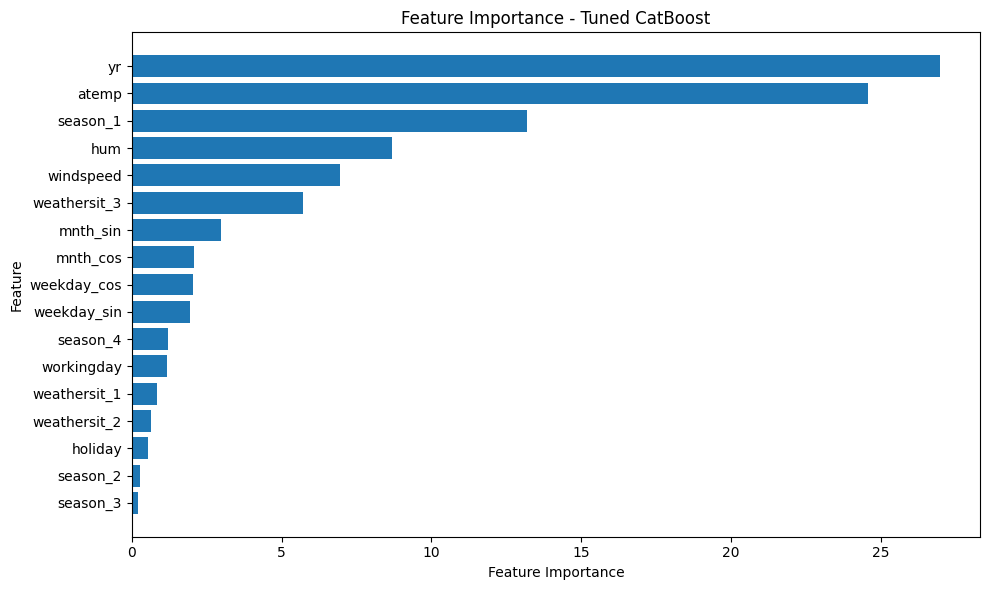

In [ ]:

# BOX 89
# Feature Importance - Final Tuned CatBoost

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
cat_feature_importance = final_cat_model.get_feature_importance()

# Create feature importance DataFrame
cat_fi_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": cat_feature_importance
})

# Sort from most important to least important
cat_fi_df = cat_fi_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("CatBoost Tuned - Feature Importance")
print("=" * 50)

display(cat_fi_df)

# Plot
plt.figure(figsize=(10, 6))

plt.barh(
    cat_fi_df["Feature"],
    cat_fi_df["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Tuned CatBoost")

plt.tight_layout()
plt.show()

SHAP values calculated successfully.
SHAP shape: (148, 17)


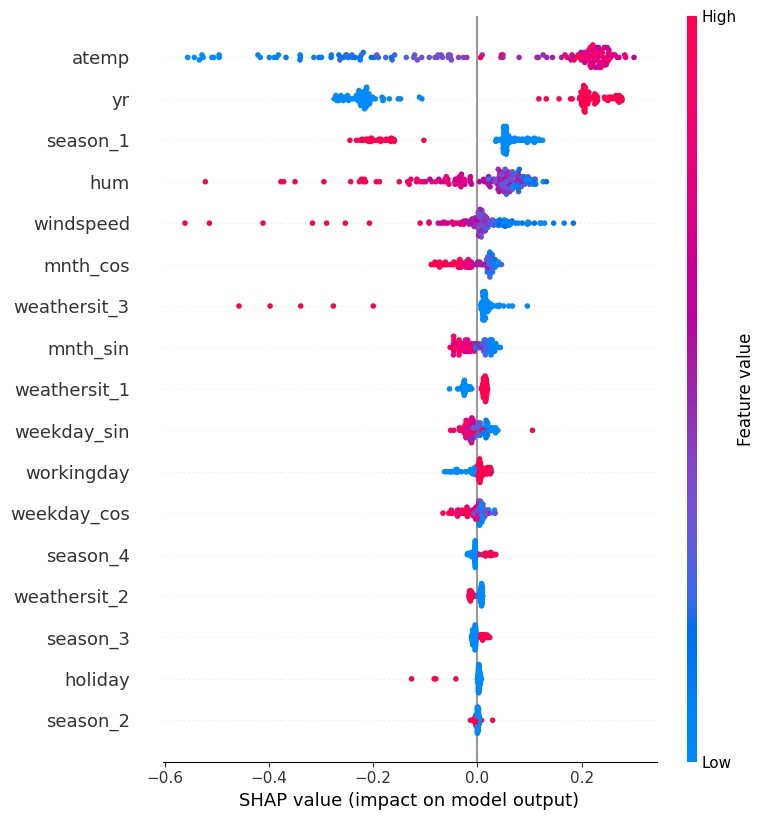

In [ ]:
# BOX 90
# SHAP Analysis - Final Tuned CatBoost

import shap
import matplotlib.pyplot as plt

# Create SHAP explainer
explainer = shap.TreeExplainer(final_cat_model)

# Calculate SHAP values on test data
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully.")
print("SHAP shape:", shap_values.shape)

# SHAP Summary Plot
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X_test.columns,
    show=True
)

In [ ]:
# BOX 91
# Final CatBoost Model - Retrain on Complete Training Data

# Copy tuned parameters
final_cat_params = tuned_cat_params.copy()

# Set final training options safely
final_cat_params["loss_function"] = "RMSE"
final_cat_params["random_seed"] = 42
final_cat_params["verbose"] = False

# Create final model
final_model = CatBoostRegressor(
    **final_cat_params
)

# Retrain on complete training data
final_model.fit(
    X_train,
    y_train_log
)

print("Final CatBoost model trained successfully.")
print("Training shape:", X_train.shape)

Final CatBoost model trained successfully.
Training shape: (583, 17)


In [ ]:
# BOX 92
# Final CatBoost - Test Prediction & Evaluation

# Predict on untouched test data
final_pred_log = final_model.predict(X_test)

# Convert back to original target scale
final_pred = np.expm1(final_pred_log)

# Prevent negative predictions
final_pred = np.maximum(final_pred, 0)

# Calculate final test metrics
final_rmse = np.sqrt(
    mean_squared_error(y_test, final_pred)
)

final_mae = mean_absolute_error(
    y_test,
    final_pred
)

final_r2 = r2_score(
    y_test,
    final_pred
)

print("FINAL CATBOOST MODEL RESULTS")
print("=" * 50)
print(f"Test RMSE : {final_rmse:.2f}")
print(f"Test MAE  : {final_mae:.2f}")
print(f"Test R²   : {final_r2:.4f}")

FINAL CATBOOST MODEL RESULTS
Test RMSE : 618.07
Test MAE  : 440.42
Test R²   : 0.8891


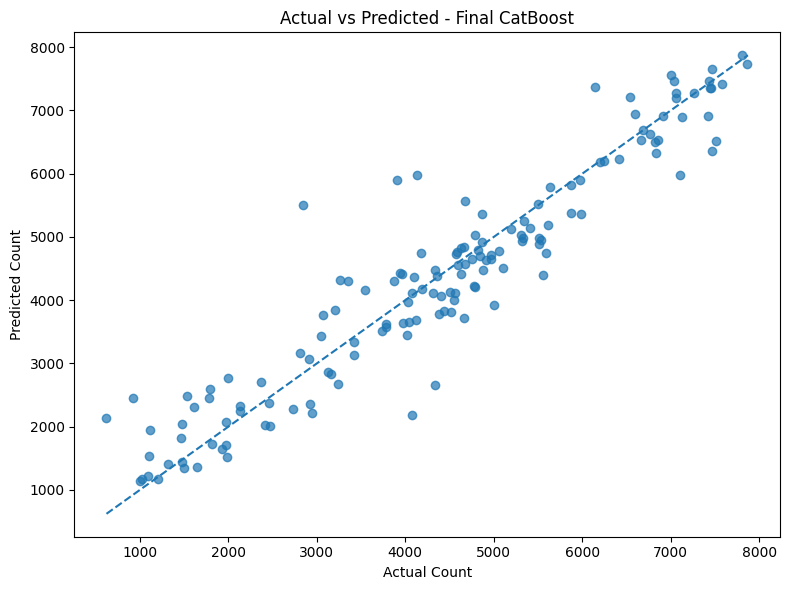

In [ ]:
# BOX 93
# Actual vs Predicted - Final CatBoost

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_pred,
    alpha=0.7
)

# Perfect prediction line
min_value = min(y_test.min(), final_pred.min())
max_value = max(y_test.max(), final_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Count")
plt.ylabel("Predicted Count")
plt.title("Actual vs Predicted - Final CatBoost")

plt.tight_layout()
plt.show()

In [ ]:
# BOX 94
# Final Model Summary

print("FINAL MODEL SUMMARY")
print("=" * 60)

print("Selected Model : Tuned CatBoost")
print(f"Test RMSE      : {final_rmse:.2f}")
print(f"Test MAE       : {final_mae:.2f}")
print(f"Test R²        : {final_r2:.4f}")

print("\nModel Selection Reason:")
print("Tuned CatBoost achieved the lowest Test RMSE")
print("and the highest Test R² among the evaluated models.")

FINAL MODEL SUMMARY
Selected Model : Tuned CatBoost
Test RMSE      : 618.07
Test MAE       : 440.42
Test R²        : 0.8891

Model Selection Reason:
Tuned CatBoost achieved the lowest Test RMSE
and the highest Test R² among the evaluated models.


### Final Conclusion

### Challanges Faced